## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [3]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Emma Chung

**Date:** 10/19/2026

Q1

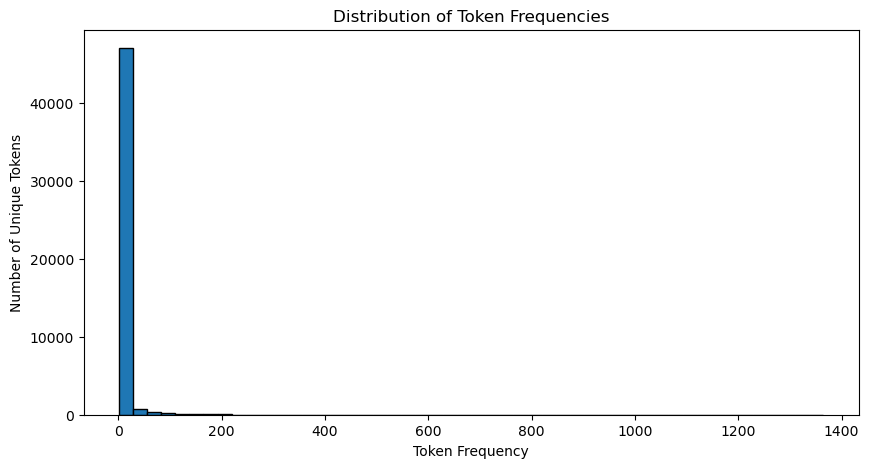

Most common tokens:
[('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795)]


In [2]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

with open("data/all_tokens.pickle", "rb") as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()

frequencies = [count for token, count in token_freq]

plt.figure(figsize=(10, 5))
plt.hist(frequencies, bins=50, edgecolor="black")
plt.xlabel("Token Frequency")
plt.ylabel("Number of Unique Tokens")
plt.title("Distribution of Token Frequencies")
plt.show()

print("Most common tokens:")
print(token_freq[:10])

The distribution of token frequencies is highly right-skewed. Most tokens occur relatively few times, while a small number appear much more frequently. The histogram has a large concentration of tokens near zero and a long tail extending to the right. This suggests that word frequencies are unevenly distributed across the emails.

Q2

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

df = pd.read_parquet("data/Phishing_clean.parquet")

X = df.drop(columns=["Email Type"])
y = df["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

train_r2 = model.score(X_train, y_train)
test_r2 = model.score(X_test, y_test)

print("Training R²:", train_r2)
print("Test R²:", test_r2)

Training R²: 0.7662702774771087
Test R²: -7.57402933885971e+23


In [4]:
coefficients = pd.Series(model.coef_, index=X.columns)

top_words = coefficients.reindex(
    coefficients.abs().sort_values(ascending=False).index
).head(10)

print("Top 10 most influential words:")
print(top_words)

Top 10 most influential words:
reserved.                                                        -2.377168e+13
url(http://images.lockergnome.com/images/issue/top-right.gif);   -1.485430e+13
underline;                                                        1.485430e+13
iit                                                               1.053085e+13
demokritos                                                       -1.053085e+13
400                                                               1.035349e+13
-0700                                                            -1.030949e+13
pudge.                                                            1.009209e+13
800                                                               1.000509e+13
1997                                                             -9.473526e+12
dtype: float64


The linear regression model predicts whether an email is phishing based on the presence of different tokens. The training and test R² scores measure how well the model explains variation in email type. The words with the largest absolute coefficients have the strongest influence on predictions when other features are held constant. Positive coefficients increase the predicted phishing score, while negative coefficients decrease it. Although the largest absolute coefficients identify the tokens with the strongest estimated effects, these coefficients should be interpreted carefully because the original regression shows signs of instability.

Q3

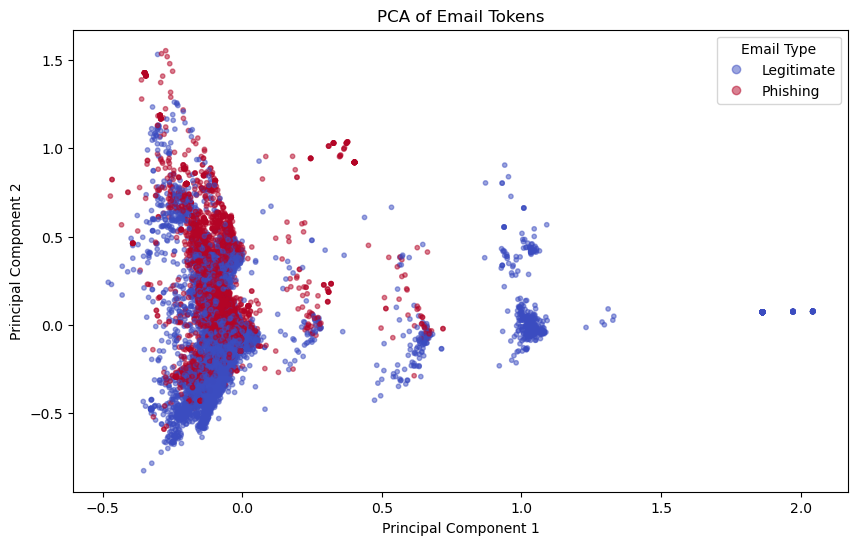

Explained variance ratio: [0.01113091 0.00860573]


In [5]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap="coolwarm",
    alpha=0.5,
    s=10
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Email Tokens")

plt.legend(
    handles=scatter.legend_elements()[0],
    labels=["Legitimate", "Phishing"],
    title="Email Type"
)

plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)

The PCA scatter plot shows considerable overlap between phishing and legitimate emails, especially in the main cluster. However, there are some smaller clusters that contain mostly legitimate emails. This suggests that the first two principal components capture some differences between email types, but they are not enough to clearly separate phishing from legitimate emails.

Q4

In [6]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression

pca_full = PCA(
    n_components=2610,
    svd_solver="randomized",
    random_state=42
)

X_train_pca = pca_full.fit_transform(X_train)
X_test_pca = pca_full.transform(X_test)

pca_model = LinearRegression()
pca_model.fit(X_train_pca, y_train)

pca_train_r2 = pca_model.score(X_train_pca, y_train)
pca_test_r2 = pca_model.score(X_test_pca, y_test)

print("Original Regression:")
print("Training R²:", train_r2)
print("Test R²:", test_r2)

print("\nPCA Regression:")
print("Training R²:", pca_train_r2)
print("Test R²:", pca_test_r2)

Original Regression:
Training R²: 0.7662702774771087
Test R²: -7.57402933885971e+23

PCA Regression:
Training R²: 0.7661790402020927
Test R²: 0.6684498278537181


The original linear regression had a training R² of 0.7663 but an extremely negative test R² of approximately −7.57 × 10²³. Using diagnostic code, I was able to see that the original model produced predictions in the trillions, indicating numerical instability. After applying PCA with 2,610 components, the training R² remained similar at 0.7662, while the test R² improved to 0.6684. This suggests that PCA helped stabilize the regression by reducing redundancy and transforming the original predictors into uncorrelated components.

Q5

PCA is useful for high-dimensional regression because it reduces the number of features while preserving much of the variation in the data. It also creates uncorrelated components, which reduces redundancy between predictors. In this assignment, PCA greatly improved the test R² while maintaining a similar training R², suggesting that it helped the model generalize better to new emails. However, PCA also makes the model harder to interpret because the components combine multiple words rather than representing individual tokens.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]